In [4]:
!pip install stable_baselines3 gymnasium[box2d]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 105.8 MB/s eta 0:00:00


In [5]:
import os
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import EvalCallback

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
def train_ppo(env_name, total_timesteps=300_000, ent_coef=0.0, log_dir="./logs"):

    print("\n====================")
    print("Env:", env_name)
    print("Ent_coef:", ent_coef)
    print("====================\n")

    os.makedirs(log_dir, exist_ok=True)

    env = make_vec_env(env_name, n_envs=1)
    env_val = make_vec_env(env_name, n_envs=1)

    eval_callback = EvalCallback(
        env_val,
        best_model_save_path=log_dir,   # best_model.zip ici
        log_path=log_dir,
        eval_freq=25_000,
        deterministic=True,
        n_eval_episodes=10
    )

    model = PPO(
        "MlpPolicy",
        env,
        verbose=0,
        ent_coef=ent_coef,
    )

    model.learn(
        total_timesteps=total_timesteps,
        callback=eval_callback
    )

    # 💾 IMPORTANT : sauvegarde finale garantie
    model.save(f"{log_dir}/final_model.zip")

    mean_reward, std_reward = evaluate_policy(model, env, n_eval_episodes=10)

    print("\nFINAL RESULT:")
    print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

    env.close()
    env_val.close()

    return model, mean_reward

In [7]:
import gymnasium as gym
env_name = "LunarLanderContinuous-v3"

configs = [
    {"name": "default", "ent_coef": 0.0},
    {"name": "low_entropy", "ent_coef": 0.001},
    {"name": "medium_entropy", "ent_coef": 0.01},
]

results = {}

for cfg in configs:
    log_dir = f"./logs/{env_name}_{cfg['name']}"

    model, reward = train_ppo(
        env_name=env_name,
        ent_coef=cfg["ent_coef"],
        log_dir=log_dir
    )

    results[cfg["name"]] = reward


Env: LunarLanderContinuous-v3
Ent_coef: 0.0



<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute
/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.12/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packages
  declare_namespace(pkg)
/usr/local/lib/python3.12/dist-packages/

Eval num_timesteps=25000, episode_reward=-68.74 +/- 126.54
Episode length: 204.80 +/- 54.93
New best mean reward!
Eval num_timesteps=50000, episode_reward=-160.58 +/- 21.59
Episode length: 908.90 +/- 150.85
Eval num_timesteps=75000, episode_reward=126.07 +/- 85.87
Episode length: 748.10 +/- 58.57
New best mean reward!
Eval num_timesteps=100000, episode_reward=170.08 +/- 70.19
Episode length: 505.80 +/- 168.16
New best mean reward!
Eval num_timesteps=125000, episode_reward=103.40 +/- 128.01
Episode length: 556.80 +/- 217.39
Eval num_timesteps=150000, episode_reward=164.22 +/- 88.97
Episode length: 578.90 +/- 49.27
Eval num_timesteps=175000, episode_reward=128.08 +/- 130.05
Episode length: 572.90 +/- 87.18
Eval num_timesteps=200000, episode_reward=118.69 +/- 95.34
Episode length: 584.50 +/- 99.22
Eval num_timesteps=225000, episode_reward=127.62 +/- 117.10
Episode length: 399.50 +/- 87.79
Eval num_timesteps=250000, episode_reward=-2.52 +/- 131.01
Episode length: 550.70 +/- 250.59
Eval num

In [10]:
import os

for cfg in configs:
    path = f"./logs/{env_name}_{cfg['name']}/final_model.zip"

    if os.path.exists(path):
        print(f"✅ Model saved: {path}")
    else:
        print(f"❌ Missing: {path}")

✅ Model saved: ./logs/LunarLanderContinuous-v3_default/final_model.zip
✅ Model saved: ./logs/LunarLanderContinuous-v3_low_entropy/final_model.zip
✅ Model saved: ./logs/LunarLanderContinuous-v3_medium_entropy/final_model.zip


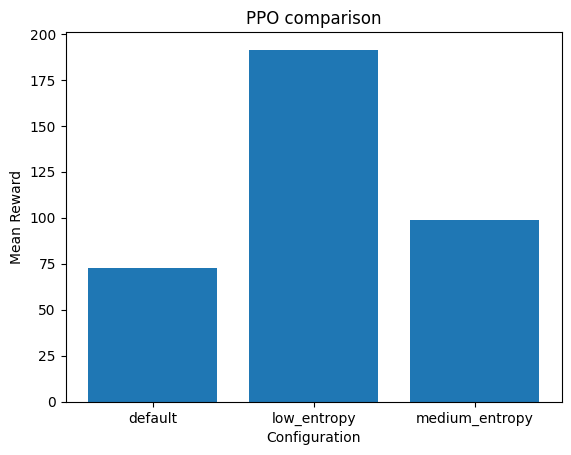

In [8]:
plt.figure()

names = list(results.keys())
values = list(results.values())

plt.bar(names, values)

plt.title("PPO comparison")
plt.ylabel("Mean Reward")
plt.xlabel("Configuration")

plt.show()

In [12]:
from stable_baselines3 import PPO
import gymnasium as gym

env = gym.make("LunarLanderContinuous-v3", render_mode="human")

models = {
    "default": "./logs/LunarLanderContinuous-v3_default/final_model.zip",
    "low_entropy": "./logs/LunarLanderContinuous-v3_low_entropy/final_model.zip",
    "medium_entropy": "./logs/LunarLanderContinuous-v3_medium_entropy/final_model.zip",
}

for name, path in models.items():
    print(f"\n=== Testing {name} ===")

    model = PPO.load(path)
    obs, _ = env.reset()

    total_reward = 0

    for _ in range(1000):
        action, _ = model.predict(obs)
        obs, reward, done, truncated, _ = env.step(action)
        total_reward += reward

        if done or truncated:
            break

    print(f"Reward: {total_reward:.2f}")


=== Testing default ===
Reward: -49.08

=== Testing low_entropy ===
Reward: 149.28

=== Testing medium_entropy ===
Reward: 108.84


In [8]:
!pip install imageio imageio-ffmpeg

In [10]:
!ls

logs  sample_data


In [1]:
!pip install gymnasium[box2d] stable-baselines3[extra]

In [13]:
from stable_baselines3 import PPO
import gymnasium as gym

model = PPO.load("./logs/LunarLanderContinuous-v3_low_entropy/final_model.zip")

In [15]:
env = gym.make("LunarLanderContinuous-v3", render_mode="human")

obs, _ = env.reset()

for _ in range(1000):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = env.step(action)

    if terminated or truncated:
        obs, _ = env.reset()

env.close()

In [14]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from stable_baselines3 import PPO

env = gym.make("LunarLanderContinuous-v3", render_mode="rgb_array")

env = RecordVideo(
    env,
    video_folder="./video",
    name_prefix="ppo_lander",
    episode_trigger=lambda x: True  # record every episode
)

model = PPO.load("./logs/LunarLanderContinuous-v3_low_entropy/final_model.zip")

obs, _ = env.reset()

for _ in range(1000):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = env.step(action)

    if terminated or truncated:
        obs, _ = env.reset()
        break

env.close()

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
